# Student Performance Predictor: EDA & Modelling

This notebook documents how the model behind the web app was built:

1. **Data**: the [UCI Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student+performance) (Cortez & Silva, 2008), with 1,044 real students from two Portuguese secondary schools (Maths and Portuguese courses).
2. **EDA**: target distribution, the *non-sitter* problem, and feature relationships.
3. **Modelling**: 5 models compared with cross-validation against a naive baseline.
4. **Explainability**: SHAP values and residual analysis.

Training for the app is reproducible with `python -m predictor.ml.train`; this notebook explains the decisions behind it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from predictor.ml.dataset import build_features, load_raw

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GRAY = "#2a78d6", "#e34948", "#8f8e86"

raw = load_raw()
print(raw.shape)
raw.head()

(1044, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,math
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,math
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,math
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,math
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,math


## 1. Data quality

In [2]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
raw["subject"].value_counts()

Missing values: 0
Duplicate rows: 0


subject
portuguese    649
math          395
Name: count, dtype: int64

## 2. The target, and the students who never sat the exam

Grades are on a 0–20 scale (converted to 0–100 in the app). There is a spike at exactly **0**.

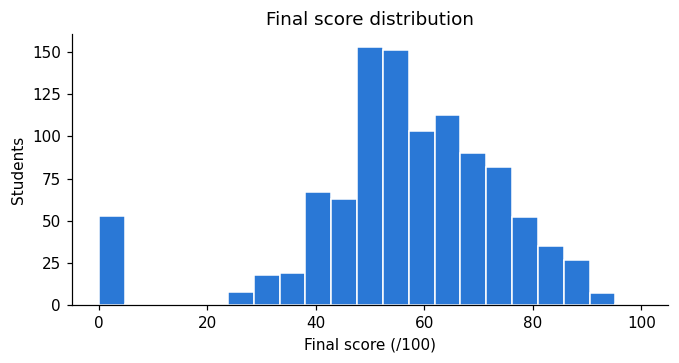

53 students have a final grade of 0
Their mean period-1 grade: 37.0 / 100
Their mean absences: 0.0 vs 4.7 for everyone else


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(raw["G3"] * 5, bins=21, color=BLUE, edgecolor="white")
ax.set(xlabel="Final score (/100)", ylabel="Students", title="Final score distribution")
plt.show()

zeros = raw[raw["G3"] == 0]
print(f"{len(zeros)} students have a final grade of 0")
print("Their mean period-1 grade:", round(zeros["G1"].mean() * 5, 1), "/ 100")
print("Their mean absences:", round(zeros["absences"].mean(), 1),
      "vs", round(raw.loc[raw["G3"] > 0, "absences"].mean(), 1), "for everyone else")

These students were already struggling in period 1 (37/100 on average), and then scored exactly 0: they **did not sit the final exam** (dropout). Tellingly, **every one of them has 0 recorded absences**. That's almost certainly a recording artifact (absences stop being logged once a student leaves), not perfect attendance.

This matters: left in, these rows teach the model that **fewer absences → a score of 0**, which makes absences look *good* for grades. The plot below shows the correlation flipping once they are removed.

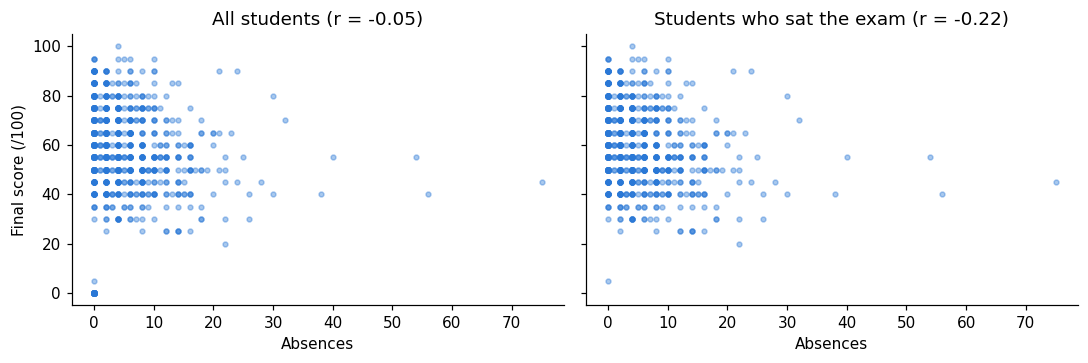

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, df) in zip(axes, [("All students", raw), ("Students who sat the exam", raw[raw.G3 > 0])]):
    r = np.corrcoef(df["absences"], df["G3"])[0, 1]
    ax.scatter(df["absences"], df["G3"] * 5, s=10, alpha=0.4, color=BLUE)
    ax.set(title=f"{title} (r = {r:+.2f})", xlabel="Absences")
axes[0].set_ylabel("Final score (/100)")
plt.tight_layout(); plt.show()

**Decision:** the app predicts the final score *of a student who sits the exam*, so the 53 non-sitters are excluded (`build_features(drop_non_sitters=True)`). Predicting dropout risk is a different (classification) problem and a good future extension.

## 3. Feature relationships

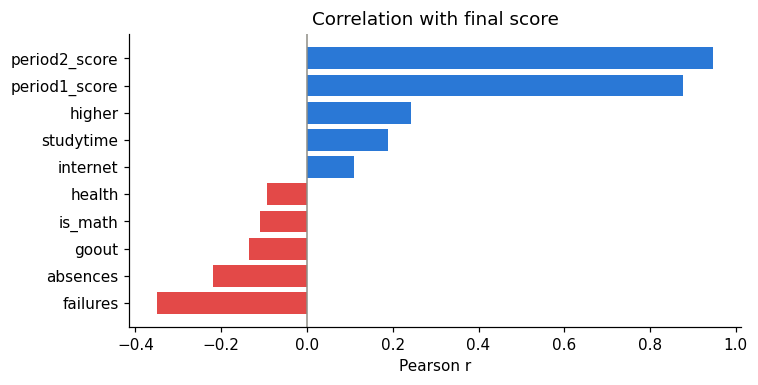

In [5]:
X, y = build_features(raw)
df = X.assign(final_score=y)
corr = df.corr()["final_score"].drop("final_score").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(corr.index, corr.values, color=[RED if v < 0 else BLUE for v in corr.values])
ax.axvline(0, color=GRAY, lw=1)
ax.set(title="Correlation with final score", xlabel="Pearson r")
plt.tight_layout(); plt.show()

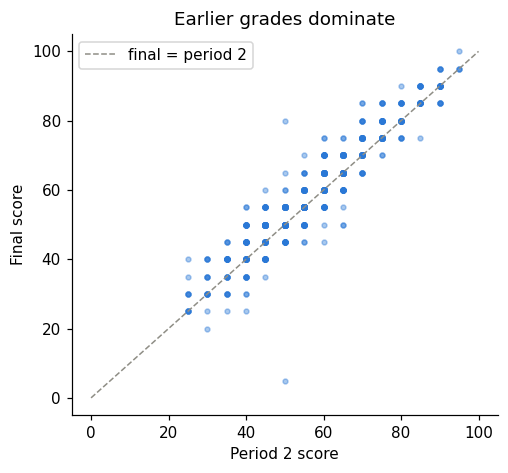

In [6]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X["period2_score"], y, s=10, alpha=0.4, color=BLUE)
ax.plot([0, 100], [0, 100], color=GRAY, ls="--", lw=1, label="final = period 2")
ax.set(xlabel="Period 2 score", ylabel="Final score", title="Earlier grades dominate")
ax.legend(); plt.show()

Earlier-period grades are by far the strongest predictors. That motivates a **naive baseline** that any model must beat: *final score = period 2 score*.

## 4. Model comparison

`predictor/ml/train.py` compares five models with 5-fold cross-validation on the training split (hyperparameters tuned with an inner grid search, i.e. nested CV), then evaluates the winner once on a 20% held-out test set.

In [7]:
metrics = json.loads(Path("../models/metrics.json").read_text())
table = pd.DataFrame([{"model": r["model"], **r["cv"]} for r in metrics["comparison"]])
table.sort_values("rmse").reset_index(drop=True)

,model,r2,mae,rmse
0,Linear Regression,0.904,3.31,4.52
1,Ridge Regression,0.904,3.31,4.52
2,Gradient Boosting,0.902,3.28,4.56
3,Random Forest,0.896,3.40,4.69
4,Monotonic Gradient Boosting,0.896,3.35,4.69


In [8]:
sel, base = metrics["selected"], metrics["baseline"]
pd.DataFrame({sel["model"]: sel["test"], f"Baseline ({base['name']})": base["test"]}).T

,r2,mae,rmse
Linear Regression,0.910,3.52,4.35
Baseline (final = period 2 score),0.883,3.47,4.94


**Takeaways**

* All models land at R² ≈ 0.90. The simplest one, **linear regression**, has the lowest CV error, so it is selected: it is also the easiest to explain.
* On the held-out test set it cuts RMSE by ~12% versus the baseline and raises R², while MAE is roughly equal. The model's gain is in avoiding *large* errors, i.e. students whose final result differs substantially from their period-2 grade.
* A gradient-boosting model with **monotonic constraints** (more absences can never raise a score) was tried as well; it's competitive but not better.

## 5. Explainability with SHAP

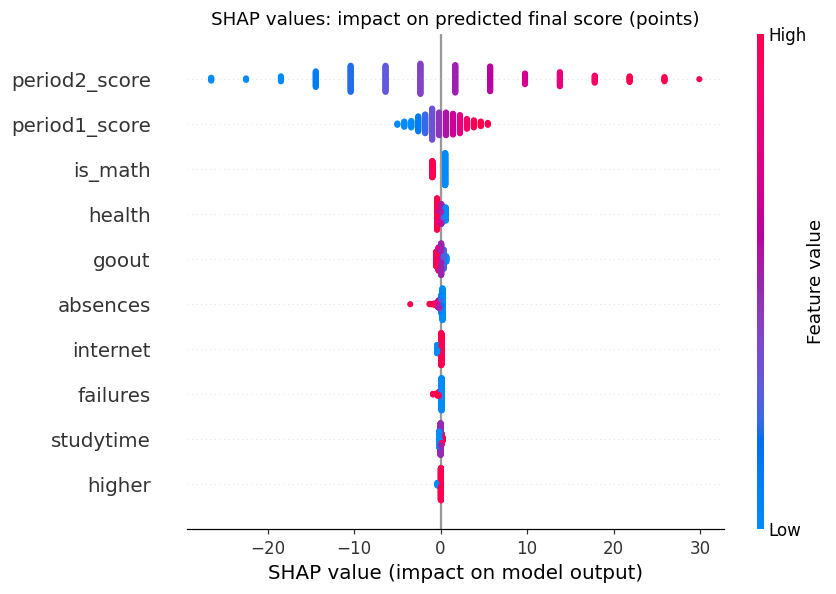

In [9]:
import joblib
import shap

artifact = joblib.load("../models/model.joblib")
model, background = artifact["model"], artifact["background"]
explainer = shap.Explainer(model, background)
shap_values = explainer(X.sample(300, random_state=0))
shap.plots.beeswarm(shap_values, show=False)
plt.title("SHAP values: impact on predicted final score (points)")
plt.tight_layout(); plt.show()

The web app shows a per-prediction version of this: how much each input moved *your* prediction compared with a typical student, plus what-if suggestions for the inputs a student can change. These are associations learned from observational data, not causal effects (e.g. the small negative *health* effect is almost certainly a confounder).

## 6. Residuals and prediction intervals

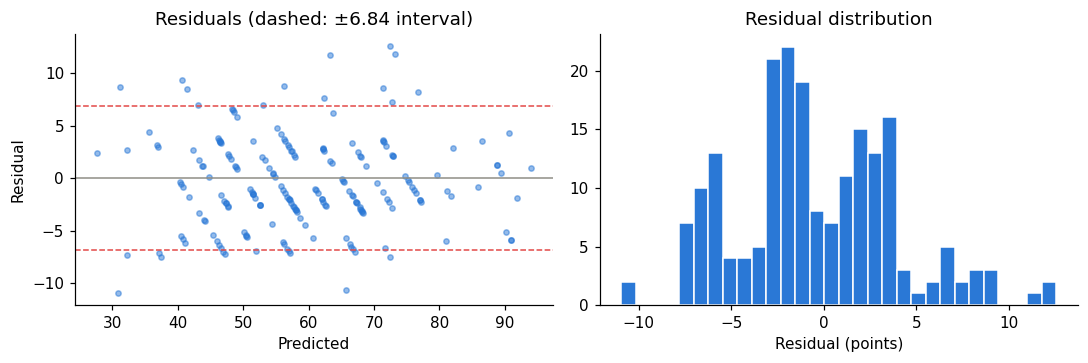

Test coverage of the 90% interval: 87.4%


In [10]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
m = clone(model).fit(X_tr, y_tr)
resid = y_te - m.predict(X_te)
hw = metrics["interval"]["halfwidth"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].scatter(m.predict(X_te), resid, s=12, alpha=0.5, color=BLUE)
axes[0].axhline(0, color=GRAY, lw=1)
for s in (-hw, hw):
    axes[0].axhline(s, color=RED, ls="--", lw=1)
axes[0].set(xlabel="Predicted", ylabel="Residual", title=f"Residuals (dashed: ±{hw} interval)")
axes[1].hist(resid, bins=30, color=BLUE, edgecolor="white")
axes[1].set(xlabel="Residual (points)", title="Residual distribution")
plt.tight_layout(); plt.show()
print(f"Test coverage of the 90% interval: {np.mean(np.abs(resid) <= hw):.1%}")

The ±interval is the 90th percentile of *out-of-fold* absolute residuals on the training data (a split-conformal style approach), so it's calibrated on data the model didn't see. Coverage on the test set is close to the 90% target.

## 7. Limitations & next steps

* 991 students from two schools in Portugal (2005–06): results may not transfer to other education systems.
* Earlier grades carry most of the signal; without them R² drops to ~0.2. An *early-warning* model (no grades) and a *dropout-risk* classifier would be valuable extensions.
* Effects are correlational, so the recommendations are what-if estimates, not guarantees.